# Liquidez: primera ruptura, recuperación y dependencia temporal
## Resumen
Comparamos IID y Markov persistente con los mismos marginales diarios. La reserva necesaria depende de las secuencias, no solo de la caja al final. Datos sintéticos, objetivo5% arbitrario. Los números se calculan abajo; no es calibración bancaria ni requerimiento regulatorio.

## Modelo y supuestos
$C_t=C_{t-1}+g(S_t)$ y después $S_{t+1}\sim P(S_t,\cdot)$. Flujosg=[+1,−2],π=[.8,.2]. IID tiene ambasfilasπ; persistenteP=[[.95,.05],[.2,.8]]. Se verificaπP=π, así que cada día posee mismos marginales y media+.4.

$\tau=\inf\{t\ge1:C_t<0\}$: cero no rompe. El DPvivo absorbe la masa que cruza la frontera. $P(\tau>H)+\sum_{t=1}^H P(\tau=t)=1$. No confundirτ>H con tiempo de ruptura igualaH+1. Absorción mide historia, no política de liquidación.

### Hipótesis y pregunta
Con reserva6,H20,¿persistencia aumenta primera ruptura≥10pp respectoIID?¿La ruptura persistente supera terminal negativo≥2pp?Son umbrales preespecificados enconfig. No existe una afirmación universal de que toda persistencia aumenta todo riesgo.

In [1]:
from pathlib import Path
import csv,json,math
from IPython.display import display,Image
from src.breach import first_breach,minimum_buffer
root=Path.cwd()
metrics=json.loads((root/'results/metrics.json').read_text())
summary=list(csv.DictReader((root/'results/summary.csv').open()))
for row in summary: print(row)
print('Errororáculoexhaustivo',metrics['exhaustive_oracle_error'])
assert metrics['hypothesis_passed']

{'model': 'iid', 'first_breach': '0.02927038686540335', 'terminal_negative': '0.009981786320724306', 'recovered_breach': '0.01928860054467904', 'survival': '0.9707296131345975', 'minimum_buffer': '5', 'mass_error': '8.881784197001252e-16'}
{'model': 'persistent', 'first_breach': '0.25722509658919335', 'terminal_negative': '0.1579285263886243', 'recovered_breach': '0.09929657020056903', 'survival': '0.7427749034108063', 'minimum_buffer': '22', 'mass_error': '4.440892098500626e-16'}
Errororáculoexhaustivo 0.0


## Datos y resultados
DPfinito sin sampling estima la probabilidad bajo matrizconocida. MonteCarlo30semillas×20.000draws por modelo aporta un contraste computacional independiente; su variación no cuantifica incertidumbre deP ni de flujosreales. Curva0..40 identifica el mínimo entero que cumpleobjetivo5% dentro del modelo.

iid MC RMSE primera ruptura 0.0010793806011848677
persistent MC RMSE primera ruptura 0.003167470296952316
Flujo esperado por día 0.4


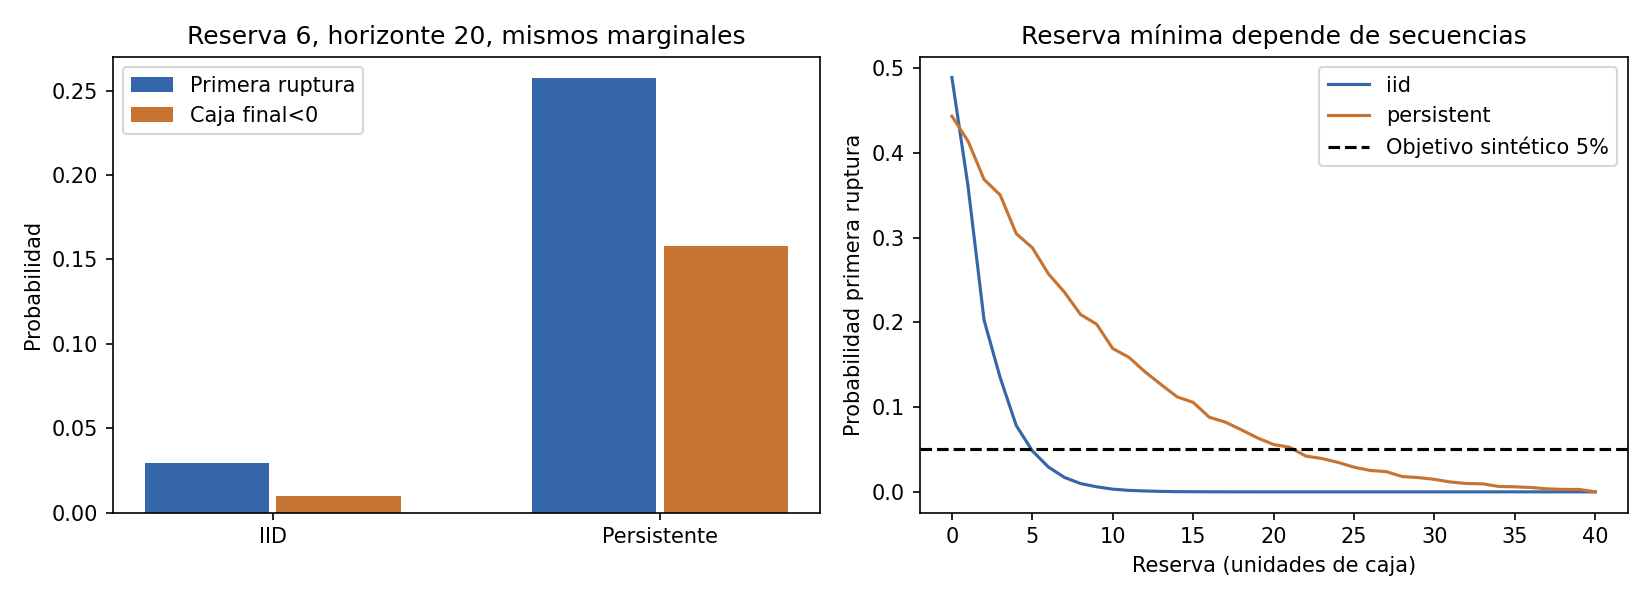

In [2]:
display(Image(filename=str(root/'results/audit.png')))
trials=list(csv.DictReader((root/'results/trials.csv').open()))
for name in ['iid','persistent']:
 errors=[float(r['error']) for r in trials if r['model']==name]
 print(name,'MC RMSE primera ruptura',math.sqrt(sum(e*e for e in errors)/len(errors)))
print('Flujo esperado por día',metrics['expected_daily_cash_increment'])

## Contraejemplos y fronteras
Desde caja1,flujos−2,+3: hay ruptura día1 y recuperación día2. Saldo final positivo no implica haber sobrevivido. ParaH1,ambasmatrices dan el mismo riesgo, porque aún no se usa la persistencia de transición. Con reserva0,H20, la curva persistente44,315% queda por debajo de IID48,880%: no hay orden universal entre matrices. Estos contraejemplos impiden sobregeneralizar el efecto.

In [3]:
r=first_breach(1,2,[-2,3],[[0,1],[0,1]],[1,0])
assert r.first_breach==(1.,0.) and r.terminal_negative==0
assert first_breach(2,1,[-2],[[1]],[1]).breach_probability==0
pi=[.8,.2]
models=[[[.8,.2],[.8,.2]],[[.95,.05],[.2,.8]]]
assert first_breach(1,1,[1,-2],models[0],pi).breach_probability==first_breach(1,1,[1,-2],models[1],pi).breach_probability
print('Casorecuperación',r)
print('Checks passed')

Casorecuperación BreachResult(first_breach=(1.0, 0.0), terminal_negative=0.0, survival=0.0, maximum_mass_error=0.0, peak_states=1)
Checks passed


## Interpretación y límites
El motorC++ existente ya detecta primera ruptura por trayectoria; esteMVP añade oráculo y persistencia, no corrige ese comportamiento. Las reservas5/22 son del escenario/objetivo. Faltan calibración, líneasdecrédito, reacción de clientes, activosliquidables y múltiplesmonedas. El comparador terminal permite recuperación contrafactual tras déficit: no presume acceso real a financiación.

In [4]:
for row in csv.DictReader((root/'results/performance.csv').open()):print(row)
print('Tiempo/memoriaPython global',metrics['seconds'],metrics['peak_tracemalloc_bytes'])

{'horizon': '20', 'seconds': '0.0005486430000019027', 'peak_states': '42', 'mass_error': '4.440892098500626e-16'}
{'horizon': '50', 'seconds': '0.006228444999919702', 'peak_states': '102', 'mass_error': '1.1102230246251565e-15'}
{'horizon': '100', 'seconds': '0.016577748000031534', 'peak_states': '202', 'mass_error': '2.3314683517128287e-15'}
Tiempo/memoriaPython global 1.143788058000041 1431602


## Siguiente iteración
Evaluar incertidumbre de la matrizP y capacidad de fondeo antes de usar el modelo como soporte de decisión. Cinco fuentes primarias verificadas e informe14p explican alcance y fallos. ElDP es exacto bajo discretización/modelo conocidos hasta precisiónflotante; no garantiza liquidez real.